#### Create a simple machine learning pipeline using a dataset of your choice. This pipeline
#### should include data loading, a basic exploratory data analysis, model training using a decision
#### tree classifier, and model validation (using train-test split).
Deliverables:

● A Jupyter notebook containing the code and brief comments explaining each step.

● A summary report discussing the choice of model, the model’s performance, and
potential ways to improve it.

In [18]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

##### Loading the cleaned laptop prices dataset
##### Since i will be using decision tress and laptop prices is a continuous target (Price), I will be converting prices into categories (Low, Medium, High, Very High) to make this valid classification problem.

In [19]:
laptops = pd.read_csv(r"C:\Users\BerniceBoateng\Desktop\machine-learning-zoomcamp\cleaned_laptop_data.csv")
laptops.head(3)

,company,typename,inches,ram,weight,price,screen_type,screen_width,screen_height,touchscreen,cpu_name,cpu_brand,cpu_speed,hdd,ssd,hybrid,flash_storage,gpu_brand,operating_system
0,apple,ultrabook,13.3,8,1.37,71378.6832,ips panel retina display,2560,1600,0,intel core i5,intel core i5,2.3,0,128,0,0,intel iris,mac
1,apple,ultrabook,13.3,8,1.34,47895.5232,standard,1440,900,0,intel core i5,intel core i5,1.8,0,0,0,128,intel hd,mac
2,hp,notebook,15.6,8,1.86,30636.0000,full hd,1920,1080,0,intel core i5,intel core i5,2.5,0,256,0,0,intel hd,others/no os


In [20]:
laptops.shape

(1244, 19)

##### Exploratory Data Analysis

In [21]:
# checking for missing values
print(laptops.isnull().sum())

company             0
typename            0
inches              0
ram                 0
weight              0
price               0
screen_type         0
screen_width        0
screen_height       0
touchscreen         0
cpu_name            0
cpu_brand           0
cpu_speed           0
hdd                 0
ssd                 0
hybrid              0
flash_storage       0
gpu_brand           0
operating_system    0
dtype: int64


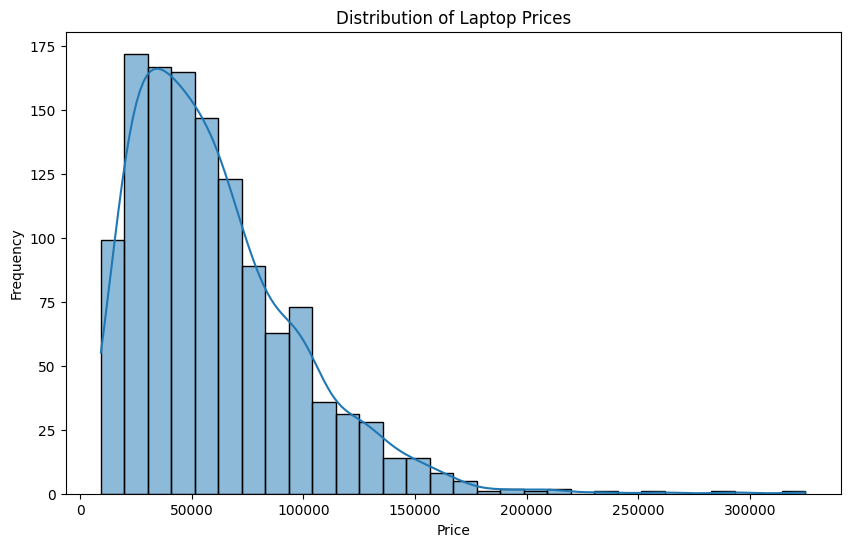

In [22]:
# visulaizing the price distribution
plt.figure(figsize=(10, 6))
sns.histplot(laptops['price'], bins=30, kde=True)
plt.title('Distribution of Laptop Prices')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

In [23]:
# summary for the price of the laptop
print(laptops['price'].describe())

count      1244.000000
mean      60606.224427
std       37424.636161
min        9270.720000
25%       32655.445200
50%       52693.920000
75%       79813.440000
max      324954.720000
Name: price, dtype: float64


#### Data Preprocessing

In [24]:
# converting prices into 4 categories (low, medium, high, very high)
# using qcut to split the prices into 4 quartiles
laptops['price_category'] = pd.qcut(laptops['price'], q=4, labels=['Low', 'Medium', 'High', 'Very High'])
print(laptops['price_category'].value_counts())

price_category
Medium       312
Low          311
High         311
Very High    310
Name: count, dtype: int64


In [25]:
laptops.head(3)

,company,typename,inches,ram,weight,price,screen_type,screen_width,screen_height,touchscreen,cpu_name,cpu_brand,cpu_speed,hdd,ssd,hybrid,flash_storage,gpu_brand,operating_system,price_category
0,apple,ultrabook,13.3,8,1.37,71378.6832,ips panel retina display,2560,1600,0,intel core i5,intel core i5,2.3,0,128,0,0,intel iris,mac,High
1,apple,ultrabook,13.3,8,1.34,47895.5232,standard,1440,900,0,intel core i5,intel core i5,1.8,0,0,0,128,intel hd,mac,Medium
2,hp,notebook,15.6,8,1.86,30636.0000,full hd,1920,1080,0,intel core i5,intel core i5,2.5,0,256,0,0,intel hd,others/no os,Low


In [ ]:
categorical_columns = laptops.select_dtypes(include=['object']).columns
print("categorical columns selected:", list(categorical_columns))



categorical columns selected: ['company', 'typename', 'screen_type', 'cpu_name', 'cpu_brand', 'gpu_brand', 'operating_system']


In [30]:
# applying one hot encoding
laptops_encoded = pd.get_dummies(laptops, columns=categorical_columns, drop_first=True) 
laptops_encoded.head(3)

,inches,ram,weight,price,screen_width,screen_height,touchscreen,cpu_speed,hdd,ssd,...,gpu_brand_intel graphics,gpu_brand_intel hd,gpu_brand_intel iris,gpu_brand_intel uhd,gpu_brand_nvidia geforce,gpu_brand_nvidia gtx,gpu_brand_nvidia quadro,operating_system_mac,operating_system_others/no os,operating_system_windows
0,13.3,8,1.37,71378.6832,2560,1600,0,2.3,0,128,...,False,False,True,False,False,False,False,True,False,False
1,13.3,8,1.34,47895.5232,1440,900,0,1.8,0,0,...,False,True,False,False,False,False,False,True,False,False
2,15.6,8,1.86,30636.0000,1920,1080,0,2.5,0,256,...,False,True,False,False,False,False,False,False,True,False


#### Model training

#### DECISION TREE CLASSIFIER

In [31]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

In [32]:
# defining my x which is the input and y which is the target
x = laptops_encoded.drop(['price', 'price_category'], axis=1)
y = laptops_encoded['price_category']

In [33]:
# splitting the data into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)   

In [34]:
# training the model
model = DecisionTreeClassifier()
model.fit(x_train, y_train)
print("Model training completed.")

Model training completed.


#### Testing models accuracy

In [35]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import joblib

In [36]:
# making predictions on the test set
y_pred = model.predict(x_test)

In [41]:
# evaluating performance
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
print(f"Models Accuracy: {accuracy * 100:.2f}%")
print("\nConfusion Matrix:", conf_matrix)
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Models Accuracy: 69.08%

Confusion Matrix: [[27  1 16 11]
 [ 0 59  4  1]
 [10 11 45  4]
 [17  0  2 41]]

Classification Report:
              precision    recall  f1-score   support

        High       0.50      0.49      0.50        55
         Low       0.83      0.92      0.87        64
      Medium       0.67      0.64      0.66        70
   Very High       0.72      0.68      0.70        60

    accuracy                           0.69       249
   macro avg       0.68      0.68      0.68       249
weighted avg       0.69      0.69      0.69       249



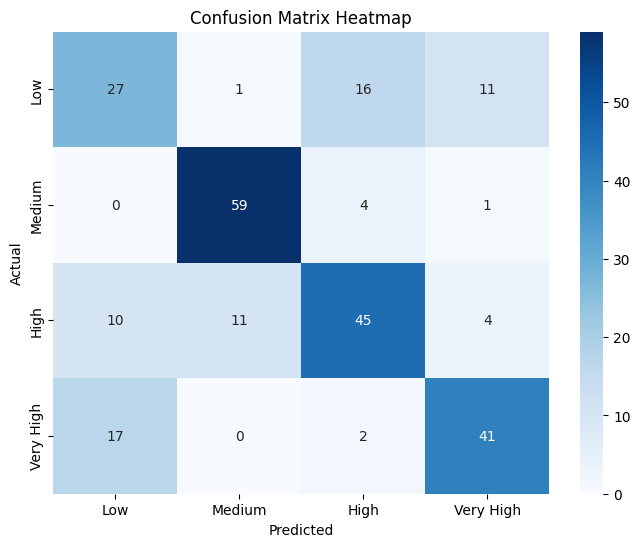

In [42]:
# visualizing the confusion matrix
plt.figure(figsize=(8,6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Low', 'Medium', 'High', 'Very High'], 
            yticklabels=['Low', 'Medium', 'High', 'Very High'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix Heatmap')
plt.show()

#### RANDOM FOREST

In [44]:
from sklearn.ensemble import RandomForestClassifier
# initializing random fores classifier using 100 trees
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# Training the Model
rf_model.fit(x_train, y_train)

RandomForestClassifier(random_state=42)

In [45]:
# evaluating Accuracy
rf_pred = rf_model.predict(x_test)
rf_accuracy = accuracy_score(y_test, rf_pred)

print(f"Random Forest Accuracy: {rf_accuracy * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

Random Forest Accuracy: 71.49%

Classification Report:
              precision    recall  f1-score   support

        High       0.54      0.56      0.55        55
         Low       0.83      0.92      0.87        64
      Medium       0.67      0.61      0.64        70
   Very High       0.79      0.75      0.77        60

    accuracy                           0.71       249
   macro avg       0.71      0.71      0.71       249
weighted avg       0.71      0.71      0.71       249



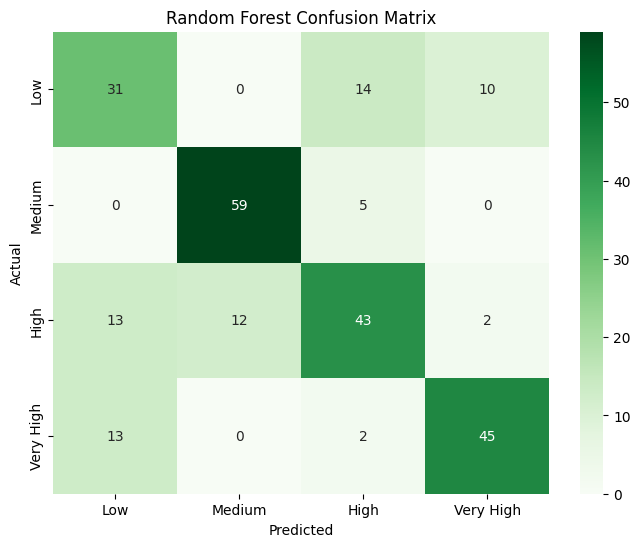

In [47]:
rf_conf_matrix = confusion_matrix(y_test, rf_pred)
plt.figure(figsize=(8,6))
sns.heatmap(rf_conf_matrix, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Low', 'Medium', 'High', 'Very High'],
            yticklabels=['Low', 'Medium', 'High', 'Very High'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Random Forest Confusion Matrix')
plt.show()


In [49]:
# performing hyperparameter tuning
from sklearn.model_selection import RandomizedSearchCV
param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
# Initializing the RandomizedSearchCV
rf_random = RandomizedSearchCV(estimator=RandomForestClassifier(random_state=42),
                               param_distributions=param_dist,
                               n_iter=10, cv=3, verbose=0, random_state=42, n_jobs=-1)

rf_random.fit(x_train, y_train)
print("Best Parameters Found:", rf_random.best_params_)

Best Parameters Found: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_depth': None}


In [50]:
# Evaluating the best model
best_rf_model = rf_random.best_estimator_
best_rf_pred = best_rf_model.predict(x_test)
best_rf_accuracy = accuracy_score(y_test, best_rf_pred)
print(f"Tuned Random Forest Accuracy: {best_rf_accuracy * 100:.2f}%")

Tuned Random Forest Accuracy: 69.08%


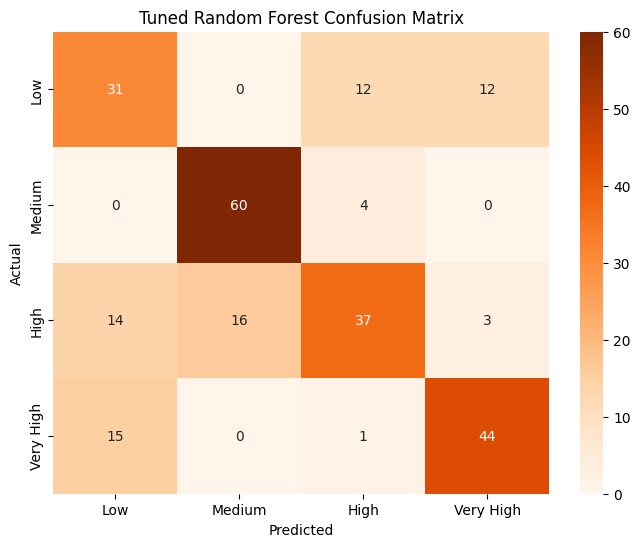

In [ ]:
# Evaluating the  model
best_rf_conf_matrix = confusion_matrix(y_test, best_rf_pred)
plt.figure(figsize=(8,6))
sns.heatmap(best_rf_conf_matrix, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Low', 'Medium', 'High', 'Very High'],
            yticklabels=['Low', 'Medium', 'High', 'Very High'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Tuned Random Forest Confusion Matrix')
plt.show()

even though after tuning the accuracy reduced the model performs better with the medim category prediction than the initial random forest model

In [53]:
# hyperparamter tuning--random forest

param_dist_advanced = {
    'n_estimators': [200, 300, 400, 500],
    'max_depth': [None, 10, 20, 30, 40, 50],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'bootstrap': [True, False]
}

rf_random_advanced = RandomizedSearchCV(estimator=RandomForestClassifier(random_state=42),
                                        param_distributions=param_dist_advanced,
                                        n_iter=50, cv=3, verbose=0, random_state=42, n_jobs=-1)
rf_random_advanced.fit(x_train, y_train)



RandomizedSearchCV(cv=3, estimator=RandomForestClassifier(random_state=42),
                   n_iter=50, n_jobs=-1,
                   param_distributions={'bootstrap': [True, False],
                                        'max_depth': [None, 10, 20, 30, 40, 50],
                                        'min_samples_leaf': [1, 2, 4],
                                        'min_samples_split': [2, 5, 10],
                                        'n_estimators': [200, 300, 400, 500]},
                   random_state=42)

In [55]:
# Evaluating the new best model
final_rf_model = rf_random_advanced.best_estimator_
final_rf_pred = final_rf_model.predict(x_test)
final_rf_accuracy = accuracy_score(y_test, final_rf_pred)
print("Best Parameters :", rf_random_advanced.best_params_)
print(f"Tuned RF Accuracy: {final_rf_accuracy * 100:.2f}%")

Best Parameters : {'n_estimators': 500, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_depth': 10, 'bootstrap': True}
Tuned RF Accuracy: 69.08%


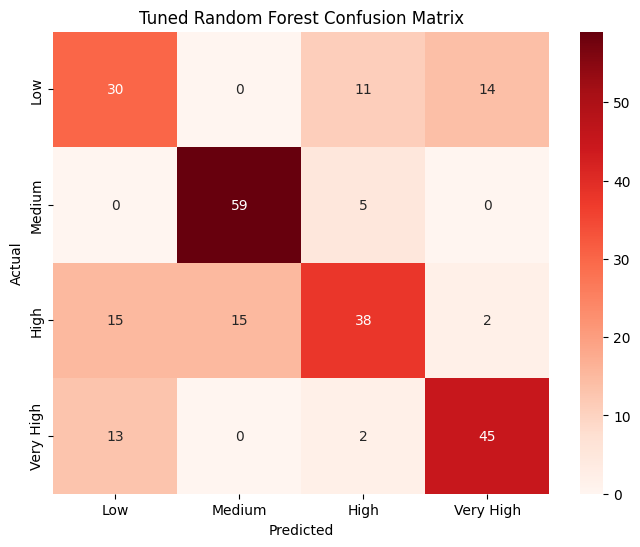

In [57]:
# Evaluating the  model
final_rf_conf_matrix = confusion_matrix(y_test, final_rf_pred)
plt.figure(figsize=(8,6))
sns.heatmap(final_rf_conf_matrix, annot=True, fmt='d', cmap='Reds',
            xticklabels=['Low', 'Medium', 'High', 'Very High'],
            yticklabels=['Low', 'Medium', 'High', 'Very High'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Tuned Random Forest Confusion Matrix')
plt.show()